# NULL: Varosha
**#30DayMapChallenge · NULL**

This notebook downloads OpenStreetMap data straight from the OSM API (no Overpass needed) and maps Varosha, the beach resort district of Famagusta, Cyprus, fenced off since 1974. Parts have reopened to visitors since 2020. Each feature is sorted into a decay stage:

| Stage | What counts |
|---|---|
| Vacant | `shop=vacant`, `building=vacant` |
| Disused | `disused:*=*`, `disused=yes` |
| Abandoned | `abandoned:*=*`, `abandoned=yes`, `building=abandoned`, `railway/highway=abandoned` |
| Ruined | `building=ruins`, `historic=ruins`, `ruins=yes` |
| Gone | `demolished:*`, `razed:*`, `was:*` |
| Brownfield | `landuse=brownfield` |

**Sections**
1. Setup and helpers
2. Download Varosha
3. Explore: every decay stage
4. Final map

Run the cells from top to bottom. The data is downloaded once, in small tiles, and cached in `osm_cache/`. Re-running a cell to tweak the styling doesn't download anything again.

## 1. Setup and helpers

In [29]:
# Run once if needed:
# %pip install requests geopandas shapely matplotlib pandas
import json, time, re, math, hashlib
from pathlib import Path
import requests
import xml.etree.ElementTree as ET
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from shapely.geometry import Point, LineString, Polygon
from shapely.ops import polygonize, unary_union

CACHE = Path("osm_cache"); CACHE.mkdir(exist_ok=True)
OUT = Path("maps"); OUT.mkdir(exist_ok=True)
OSM_API = "https://api.openstreetmap.org/api/0.6"
HEADERS = {"User-Agent": "30DayMapChallenge-null-notebook/2.0 (personal map project)"}

In [30]:
def _get_tile(bbox, depth=0, max_depth=4):
    """Download one tile from the OSM API; split it into four if it holds too many nodes."""
    s, w, n, e = bbox
    url = f"{OSM_API}/map?bbox={w},{s},{e},{n}"
    for attempt in range(4):
        try:
            r = requests.get(url, headers=HEADERS, timeout=120)
        except Exception as ex:
            print(f"    network error ({type(ex).__name__}), retrying...")
            time.sleep(5 * (attempt + 1)); continue
        if r.status_code == 200:
            return [r.content]
        if r.status_code == 400 and depth < max_depth:   # too many nodes: split
            mlat, mlon = (s + n) / 2, (w + e) / 2
            out = []
            for sub in [(s, w, mlat, mlon), (s, mlon, mlat, e), (mlat, w, n, mlon), (mlat, mlon, n, e)]:
                out += _get_tile(sub, depth + 1, max_depth)
            return out
        if r.status_code in (429, 509, 503, 504):        # rate-limited or busy: wait
            wait = 30 * (attempt + 1)
            print(f"    HTTP {r.status_code}, waiting {wait}s...")
            time.sleep(wait); continue
        raise RuntimeError(f"OSM API error {r.status_code} for {bbox}: {r.text[:200]}")
    raise RuntimeError(f"OSM API kept failing for tile {bbox}")

def _parse(xml_blobs):
    """Merge OSM XML tiles into Overpass-style elements with geometry (same shape as 'out geom')."""
    nodes, ways, rels = {}, {}, {}
    for blob in xml_blobs:
        root = ET.fromstring(blob)
        for el in root:
            tags = {t.get("k"): t.get("v") for t in el.findall("tag")}
            i = int(el.get("id", 0))
            if el.tag == "node":
                nodes[i] = (float(el.get("lon")), float(el.get("lat")), tags)
            elif el.tag == "way":
                ways[i] = ([int(nd.get("ref")) for nd in el.findall("nd")], tags)
            elif el.tag == "relation":
                mem = [(m.get("type"), int(m.get("ref")), m.get("role")) for m in el.findall("member")]
                old = rels.get(i, ([], {}))[0]
                rels[i] = (old + [m for m in mem if m not in old], tags)
    geom = lambda refs: [{"lon": nodes[r][0], "lat": nodes[r][1]} for r in refs if r in nodes]
    els = [{"type": "node", "id": i, "lon": x, "lat": y, "tags": t} for i, (x, y, t) in nodes.items() if t]
    els += [{"type": "way", "id": i, "tags": t, "geometry": geom(refs)} for i, (refs, t) in ways.items()]
    for i, (mem, t) in rels.items():
        if t.get("type") not in ("multipolygon", "boundary"):
            continue
        members = [{"type": "way", "role": role, "geometry": geom(ways[ref][0])}
                   for typ, ref, role in mem if typ == "way" and ref in ways]
        els.append({"type": "relation", "id": i, "tags": t, "members": members})
    return {"elements": els}

def load_area(name, bbox, tile=0.02):
    """Download (or load from cache) all OSM data in a bbox, fetched tile by tile."""
    f = CACHE / f"{name}_{'_'.join(str(v) for v in bbox)}.json"
    if f.exists():
        return json.loads(f.read_text())
    s, w, n, e = bbox
    lats = [s + k * tile for k in range(math.ceil((n - s) / tile))] + [n]
    lons = [w + k * tile for k in range(math.ceil((e - w) / tile))] + [e]
    tiles = [(lats[a], lons[b], lats[a + 1], lons[b + 1]) for a in range(len(lats) - 1) for b in range(len(lons) - 1)]
    print(f"Downloading {name}: {len(tiles)} tile(s) from the OSM API...")
    blobs = []
    for k, t in enumerate(tiles, 1):
        blobs += _get_tile(t)
        print(f"  tile {k}/{len(tiles)} done", end="\r")
        time.sleep(1)  # be polite to the OSM servers
    data = _parse(blobs)
    f.write_text(json.dumps(data))
    print(f"\n  {len(data['elements']):,} tagged features saved to {f}")
    return data

In [31]:
AREA_KEYS = {"building", "landuse", "amenity", "leisure", "natural", "shop", "historic",
             "ruins", "man_made", "industrial", "area", "place", "tourism", "military"}

def _is_area(tags, coords):
    if len(coords) < 4 or coords[0] != coords[-1]:
        return False
    if tags.get("area") == "no" or tags.get("natural") == "coastline":
        return False
    keys = {re.sub(r"^[a-z_]+:", "", k) for k in tags}  # disused:amenity -> amenity
    return bool(keys & AREA_KEYS) or tags.get("area") == "yes"

def to_gdf(data):
    """Convert Overpass JSON (out geom) to a GeoDataFrame in EPSG:4326."""
    rows = []
    for el in data.get("elements", []):
        tags = el.get("tags", {})
        geom = None
        if el["type"] == "node" and "lat" in el:
            geom = Point(el["lon"], el["lat"])
        elif el["type"] == "way" and "geometry" in el:
            c = [(p["lon"], p["lat"]) for p in el["geometry"]]
            if len(c) >= 2:
                geom = Polygon(c) if _is_area(tags, c) else LineString(c)
        elif el["type"] == "relation":
            lines = [LineString([(p["lon"], p["lat"]) for p in m["geometry"]])
                     for m in el.get("members", []) if m.get("type") == "way"
                     and len(m.get("geometry", [])) >= 2]
            if lines:
                polys = list(polygonize(unary_union(lines)))
                geom = unary_union(polys) if polys else unary_union(lines)
        if geom is not None and not geom.is_empty:
            rows.append({"osm_id": f'{el["type"]}/{el["id"]}', "tags": tags, "geometry": geom})
    if not rows:
        return gpd.GeoDataFrame({"osm_id": [], "tags": []}, geometry=gpd.GeoSeries([], crs=4326), crs=4326)
    gdf = gpd.GeoDataFrame(rows, geometry="geometry", crs=4326)
    if len(gdf):
        gdf["geometry"] = gdf.geometry.buffer(0).where(gdf.geom_type.isin(["Polygon", "MultiPolygon"]), gdf.geometry)
    return gdf

In [32]:
STAGES = ["Vacant", "Disused", "Abandoned", "Ruined", "Gone", "Brownfield"]

def decay_stage(tags):
    """Return the most advanced decay stage for a feature, or None."""
    k = tags.keys()
    has = lambda prefix: any(x.startswith(prefix) for x in k)
    if has("demolished:") or has("razed:") or has("was:"):
        return "Gone"
    if tags.get("building") == "ruins" or tags.get("historic") == "ruins" or tags.get("ruins") == "yes":
        return "Ruined"
    if (has("abandoned:") or tags.get("abandoned") == "yes" or tags.get("building") == "abandoned"
            or tags.get("railway") == "abandoned" or tags.get("highway") == "abandoned"):
        return "Abandoned"
    if has("disused:") or tags.get("disused") == "yes":
        return "Disused"
    if tags.get("shop") == "vacant" or tags.get("building") == "vacant":
        return "Vacant"
    if tags.get("landuse") == "brownfield":
        return "Brownfield"
    return None

def what_it_was(tags):
    """Best guess at the feature's former use, e.g. 'disused:shop=bakery' -> 'shop=bakery'."""
    for key, val in tags.items():
        m = re.match(r"^(disused|abandoned|demolished|razed|was):(.+)$", key)
        if m:
            return f"{m.group(2)}={val}"
    for key in ("building", "railway", "highway", "landuse", "shop", "historic"):
        if key in tags:
            return f"{key}={tags[key]}"
    return ""

In [33]:
def _subset(data, keep):
    return {"elements": [el for el in data["elements"] if keep(el.get("tags", {}))]}

BASE_TAGS = lambda t: ("highway" in t or t.get("natural") in ("water", "coastline", "sand", "beach")
                       or t.get("waterway") in ("river", "canal", "riverbank"))

def get_decay(name, bbox):
    gdf = to_gdf(_subset(load_area(name, bbox), lambda t: decay_stage(t) is not None))
    if len(gdf):
        gdf["stage"] = gdf["tags"].apply(decay_stage)
        gdf["was"] = gdf["tags"].apply(what_it_was)
        gdf = gdf[gdf["stage"].notna()].copy()
    else:
        gdf = gdf.assign(stage=[], was=[])
    return gdf

def get_base(name, bbox):
    gdf = to_gdf(_subset(load_area(name, bbox), BASE_TAGS))
    if not len(gdf):
        return gdf.assign(kind=[])
    def kind(t):
        if t.get("natural") == "coastline": return "coast"
        if t.get("natural") in ("water",) or t.get("waterway"): return "water"
        if t.get("natural") in ("sand", "beach"): return "sand"
        if t.get("highway") in ("motorway", "trunk", "primary", "secondary", "tertiary"): return "major"
        if "highway" in t: return "minor"
        return "other"
    gdf["kind"] = gdf["tags"].apply(kind)
    return gdf

def summarise(gdf, title):
    print(f"{title}: {len(gdf):,} features")
    if len(gdf) and "stage" in gdf:
        print(gdf["stage"].value_counts().reindex(STAGES).dropna().astype(int).to_string())
        print("\nMost common former uses:")
        print(gdf["was"].value_counts().head(10).to_string())

In [53]:
THEMES = {
    "dark": dict(bg="#0e1219", minor="#2a3140", major="#3d4658", water="#16273a", sand="#2b2820",
                 text="#e9e4da", muted="#8a8f99", ghost="#c9d3e0",
                 stages={"Vacant": "#f2d07a", "Disused": "#f0a35e", "Abandoned": "#e0663f",
                         "Ruined": "#b8443a", "Gone": "#8a8f99", "Brownfield": "#6e5a3c"}),
    "light": dict(bg="#f4f1ea", minor="#dcd7cc", major="#c4bdae", water="#cfdde3", sand="#ebe1c8",
                  text="#2b2a27", muted="#8a877f", ghost="#4a5566",
                  stages={"Vacant": "#e3b23c", "Disused": "#e07b39", "Abandoned": "#c8452c",
                          "Ruined": "#8e2a22", "Gone": "#9a958a", "Brownfield": "#b9a27a"}),
}

def _draw_base(ax, base, th):
    if not len(base):
        return
    base = base[base.geom_type != "Point"]   # skip bus stops, crossings, lamps...
    for kind, kw in [("sand", dict(color=th["sand"], lw=0)),
                     ("water", dict(color=th["water"], lw=0.6)),
                     ("coast", dict(color=th["muted"], lw=0.8)),
                     ("minor", dict(color=th["minor"], lw=0.4)),
                     ("major", dict(color=th["major"], lw=0.9))]:
        sub = base[base["kind"] == kind]
        if len(sub):
            sub.plot(ax=ax, **kw, zorder=1)

def _frame(ax, fig, bbox, th, title, subtitle, credit):
    s, w, n, e = bbox
    ax.set_xlim(w, e); ax.set_ylim(s, n)
    ax.set_aspect(1 / max(0.2, math.cos(math.radians((s + n) / 2))))
    ax.set_axis_off()
    fig.patch.set_facecolor(th["bg"]); ax.set_facecolor(th["bg"])
    fig.text(0.05, 0.96, title, fontsize=22, weight="bold", color=th["text"], va="top")
    fig.text(0.05, 0.915, subtitle, fontsize=11, color=th["muted"], va="top")
    fig.text(0.05, 0.025, credit,
             fontsize=8, color=th["muted"])

def plot_decay(decay, base, bbox, title, subtitle, theme="dark", fname=None, size=(10, 11)):
    """Option A: features coloured by decay stage over a faint street base."""
    th = THEMES[theme]
    fig, ax = plt.subplots(figsize=size, dpi=150)
    _draw_base(ax, base, th)
    handles = []
    for st in STAGES:
        sub = decay[decay["stage"] == st] if len(decay) else decay
        if not len(sub):
            continue
        col = th["stages"][st]
        dashed = st == "Gone"
        polys = sub[sub.geom_type.isin(["Polygon", "MultiPolygon"])]
        lines = sub[sub.geom_type.isin(["LineString", "MultiLineString"])]
        pts = sub[sub.geom_type == "Point"]
        if len(polys):
            if dashed:
                polys.plot(ax=ax, facecolor="none", edgecolor=col, lw=0.8, linestyle=(0, (3, 2)), zorder=3)
            else:
                is_bld = polys["tags"].apply(lambda t: any(k == "building" or k.endswith(":building") for k in t))
                wash = polys[~is_bld]
                if len(wash):  # large areas (landuse etc.) go behind as a faint wash
                    wash.plot(ax=ax, color=col, alpha=0.15 if st != "Brownfield" else 0.5, lw=0, zorder=2)
                if is_bld.any():
                    polys[is_bld].plot(ax=ax, color=col, edgecolor=col, lw=0.3, zorder=3)
        if len(lines):
            lines.plot(ax=ax, color=col, lw=1.4, linestyle=(0, (4, 2)) if dashed or st == "Abandoned" else "-", zorder=4)
        if len(pts):
            pts.plot(ax=ax, color="none" if dashed else col, edgecolor=col, markersize=14, lw=0.8, zorder=5)
        handles.append(Patch(facecolor="none" if dashed else col, edgecolor=col,
                             linestyle="--" if dashed else "-", label=f"{st}  ({len(sub):,})"))
    if handles:
        leg = ax.legend(handles=handles, loc="lower right", frameon=False, fontsize=9, labelcolor=th["text"])
    else:
        ax.text(0.5, 0.5, "No decay-tagged features found in this area",
                transform=ax.transAxes, ha="center", color=th["muted"], fontsize=12)
    _frame(ax, fig, bbox, th, title, subtitle, "Data: OpenStreetMap")
    if fname:
        fig.savefig(OUT / fname, facecolor=th["bg"], bbox_inches="tight", pad_inches=0.3)
    plt.show()

## 2. Download Varosha

In [36]:
NAME, BBOX = "varosha", (35.09, 33.935, 35.13, 33.97)   # (south, west, north, east)
base_varosha = get_base(NAME, BBOX)
decay_varosha = get_decay(NAME, BBOX)
summarise(decay_varosha, "Varosha")

Varosha: 3,778 features
stage
Disused         5
Abandoned    3639
Ruined        118
Gone           16

Most common former uses:
was
building=yes             3535
building=ruins            114
building=hotel             34
building=apartments        24
building=school            14
building=construction      12
building=house             11
highway=tertiary            9
highway=residential         7
building=church             5


## 3. Explore: every decay stage

A quick look at everything tagged as vacant, disused, abandoned, ruined or gone, before polishing.

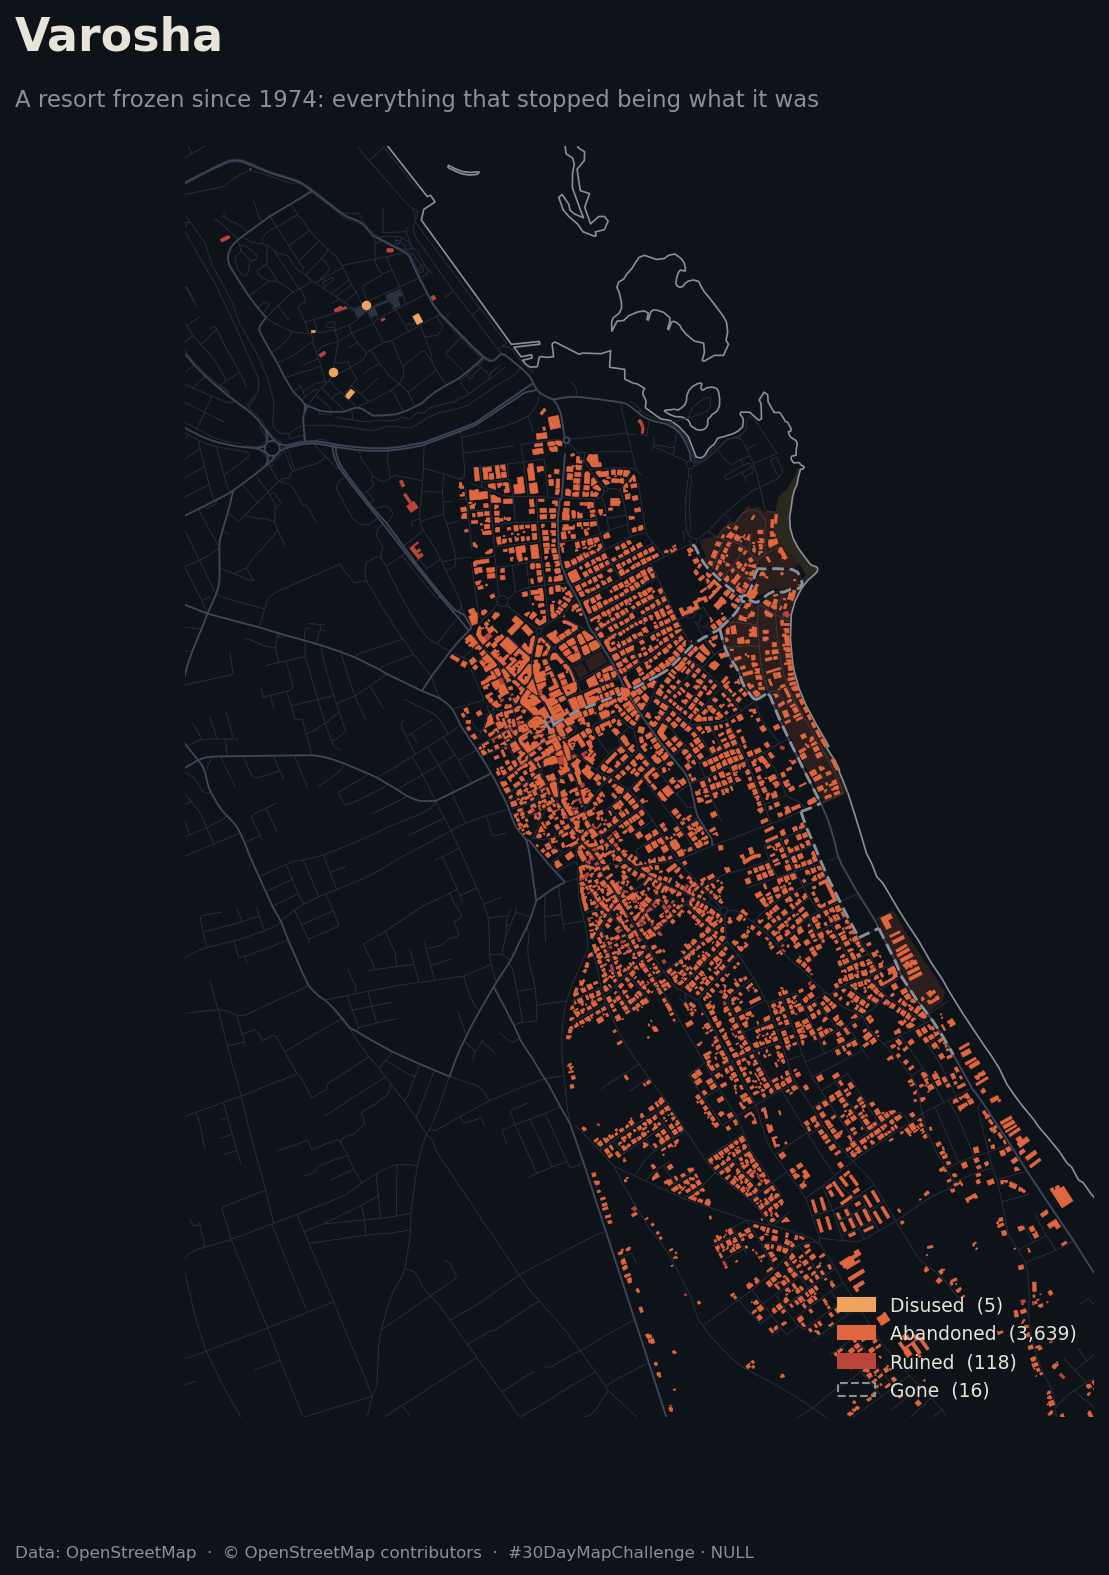

In [38]:
plot_decay(decay_varosha, base_varosha, BBOX, "Varosha", "A resort frozen since 1974: everything that stopped being what it was",
           theme="dark", fname="varosha_decay.png", size=(9, 11))

## 4. Final map

The polished version: **Gone** is dropped, and occupied buildings are drawn in quiet grey, so the edge of the dead district shows on its own.

To draw a dashed outline of the zone anyway, set `SHOW_BOUNDARY = True`. It uses an OSM polygon named Varosha or Maraş if one exists; otherwise it traces the main cluster of abandoned buildings.

Inside the district: 29 untagged (probably abandoned), 7 with signs of life


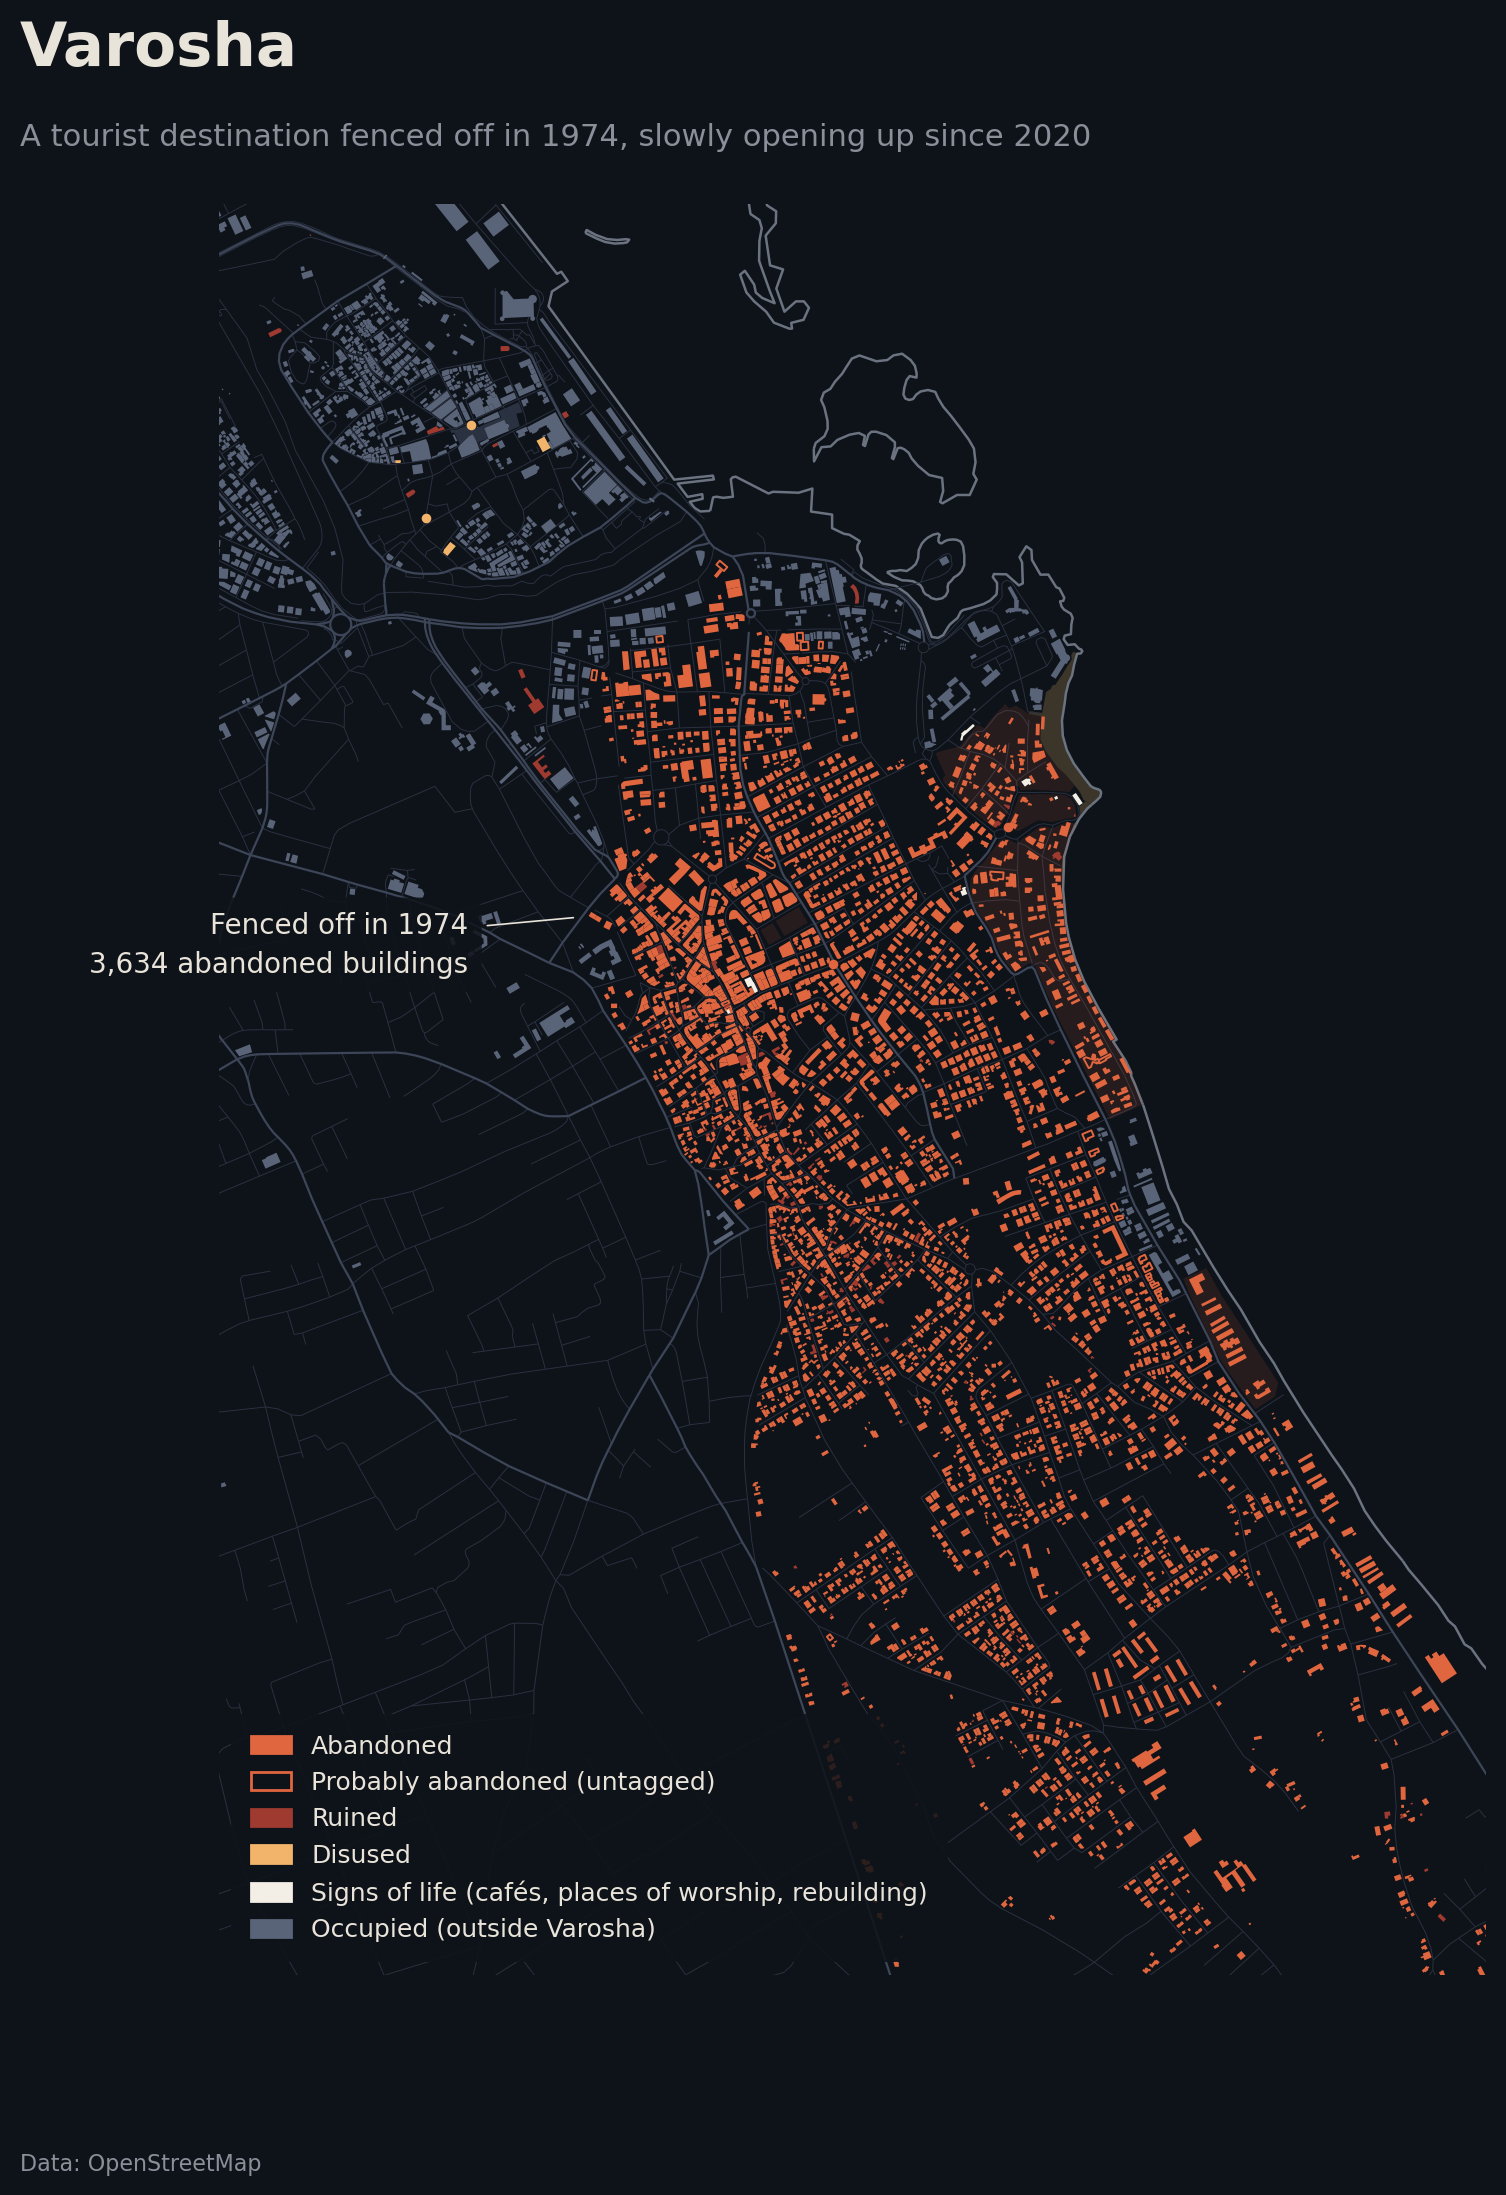

In [57]:
from shapely.geometry import MultiPolygon

V_NAMES = ("varosha", "maraş", "maras", "βαρώσια", "varoşa", "varosia")
V_KEEP = ["Abandoned", "Ruined", "Disused"]          # "Gone" dropped on purpose
SHOW_BOUNDARY = False   # True draws a dashed outline of the zone
BOUNDARY = "auto"       # if shown: "auto" = named OSM polygon if found, else traced; "traced" = always trace

def _is_building(t):
    return any(k == "building" or k.endswith(":building") for k in t)

def varosha_boundary(data, decay, mode="auto"):
    """Return (boundary polygon in EPSG:4326, how it was found)."""
    utm = decay.estimate_utm_crs()
    if mode == "auto":
        named = [el for el in data["elements"] if el["type"] in ("way", "relation")
                 and any(x in " ".join(v.lower() for k, v in el.get("tags", {}).items() if k.startswith("name"))
                         for x in V_NAMES)]
        g = to_gdf({"elements": named})
        if len(g):
            g = g[g.geom_type.isin(["Polygon", "MultiPolygon"])].to_crs(utm)
            g = g[g.area > 500_000]                      # ignore small things like a single beach or hotel
            if len(g):
                best = g.loc[g.area.idxmax()]
                name = best["tags"].get("name", "named polygon")
                return gpd.GeoSeries([best.geometry], crs=utm).to_crs(4326).iloc[0], f"OSM polygon '{name}'"
    # traced: merge abandoned buildings within ~60 m of each other, keep the biggest cluster
    blds = decay[(decay["stage"] == "Abandoned") & decay["tags"].apply(_is_building)].to_crs(utm)
    blobs = unary_union(blds.geometry.centroid.buffer(60))
    parts = list(blobs.geoms) if isinstance(blobs, MultiPolygon) else [blobs]
    main = max(parts, key=lambda p: p.area).buffer(-35).buffer(10).simplify(8)
    if main.geom_type == "MultiPolygon":
        main = max(main.geoms, key=lambda p: p.area)
    main = Polygon(main.exterior)                      # outer edge only, no holes
    return gpd.GeoSeries([main], crs=utm).to_crs(4326).iloc[0], "traced from the main cluster of abandoned buildings"

def is_in_use(t):
    """Tags that only make sense for a place that works today, or one being rebuilt."""
    return (any(k in t for k in ("amenity", "shop", "tourism", "opening_hours", "office", "craft"))
            or t.get("building") == "construction" or "construction" in t)

def plot_varosha_final(data, decay, base, bbox, fname="varosha_final.png", size=(9, 11.5)):
    th = THEMES["dark"]
    C = {"Abandoned": "#e0663f", "Ruined": "#9e3a30", "Disused": "#f2b36b",
         "living": "#5a6478", "in_use": "#f3efe6", "sand": "#3b352a", "fence": "#e9e4da"}
    fig, ax = plt.subplots(figsize=size, dpi=200)
    base = base[base.geom_type != "Point"]

    # 1. base: beach, water, coast, streets
    for kind, kw in [("sand", dict(color=C["sand"], lw=0)), ("water", dict(color=th["water"], lw=0)),
                     ("coast", dict(color="#6b7380", lw=0.9)), ("minor", dict(color=th["minor"], lw=0.35)),
                     ("major", dict(color=th["major"], lw=0.8))]:
        sub = base[base["kind"] == kind]
        if kind == "sand":
            sub = sub[sub.geom_type.isin(["Polygon", "MultiPolygon"])]
        if len(sub):
            sub.plot(ax=ax, zorder=1, **kw)

    # 2. buildings without a decay tag: split by whether they sit inside the abandoned district
    zone, _ = varosha_boundary(data, decay, "traced")
    ids = set(decay["osm_id"])
    alive = to_gdf(_subset(data, lambda t: "building" in t and decay_stage(t) is None))
    alive = alive[~alive["osm_id"].isin(ids) & alive.geom_type.isin(["Polygon", "MultiPolygon"])]
    inside = alive.representative_point().within(zone)
    in_use = alive["tags"].apply(is_in_use)
    occupied = alive[~inside]
    untagged = alive[inside & ~in_use]
    using = alive[inside & in_use]
    print(f"Inside the district: {len(untagged)} untagged (probably abandoned), {len(using)} with signs of life")
    if len(occupied):
        occupied.plot(ax=ax, color=C["living"], lw=0, zorder=2)
    if len(untagged):
        untagged.plot(ax=ax, facecolor="none", edgecolor=C["Abandoned"], lw=0.7, zorder=3)
    if len(using):
        using.plot(ax=ax, color=C["in_use"], lw=0, zorder=3.5)

    # 3. the null: abandoned / ruined / disused (large non-building areas as a faint wash behind)
    d = decay[decay["stage"].isin(V_KEEP)]
    polys = d[d.geom_type.isin(["Polygon", "MultiPolygon"])]
    bld = polys["tags"].apply(_is_building)
    for st in V_KEEP:
        wash = polys[~bld & (polys["stage"] == st)]
        if len(wash):
            wash.plot(ax=ax, color=C[st], alpha=0.12, lw=0, zorder=2.5)
    for st in V_KEEP:
        b = polys[bld & (polys["stage"] == st)]
        if len(b):
            b.plot(ax=ax, color=C[st], lw=0, zorder=3)
        other = d[(d["stage"] == st) & ~d.geom_type.isin(["Polygon", "MultiPolygon"])]
        if len(other):
            other.plot(ax=ax, color=C[st], lw=1, markersize=6, zorder=3)

    # 4. boundary (optional); the traced outline is still used to place the note
    bnd, how = varosha_boundary(data, decay, BOUNDARY if SHOW_BOUNDARY else "traced")
    if SHOW_BOUNDARY:
        print("Boundary:", how)
        gpd.GeoSeries([bnd], crs=4326).boundary.plot(ax=ax, color=C["fence"], lw=0.9,
                                                      linestyle=(0, (5, 3)), zorder=4)

    # 5. annotation at the boundary's westernmost point
    ring = bnd.exterior if bnd.geom_type == "Polygon" else max(bnd.geoms, key=lambda p: p.area).exterior
    wx, wy = min(ring.coords, key=lambda c: c[0])
    n_aband = int((bld & (polys["stage"] == "Abandoned")).sum())
    ax.annotate(f"Fenced off in 1974\n{n_aband:,} abandoned buildings",
                (wx, wy), (-40, -10), textcoords="offset points", ha="right", va="center",
                fontsize=10, color=th["text"], linespacing=1.5, zorder=6,
                bbox=dict(boxstyle="round,pad=0.5", facecolor=th["bg"], edgecolor="none", alpha=0.85),
                arrowprops=dict(arrowstyle="-", color=C["fence"], lw=0.6))

    # 6. legend
    has = lambda s: (d["stage"] == s).any()
    handles = []
    if has("Abandoned"):
        handles += [Patch(color=C["Abandoned"], label="Abandoned")]
    if len(untagged):
        handles += [Patch(facecolor="none", edgecolor=C["Abandoned"], label="Probably abandoned (untagged)")]
    handles += [Patch(color=C[s], label=s) for s in ("Ruined", "Disused") if has(s)]
    if len(using):
        handles += [Patch(color=C["in_use"], label="Signs of life (cafés, places of worship, rebuilding)")]
    handles += [Patch(color=C["living"], label="Occupied (outside Varosha)")]
    if SHOW_BOUNDARY:
        handles += [Line2D([0], [0], color=C["fence"], lw=0.9, linestyle=(0, (5, 3)), label="Fenced zone")]
    leg = ax.legend(handles=handles, loc="lower left", fontsize=9, labelcolor=th["text"],
                    frameon=True, facecolor=th["bg"], edgecolor="none", framealpha=0.85,
                    borderpad=0.8, handlelength=1.6)

    _frame(ax, fig, bbox, th, "Varosha", "A tourist destination fenced off in 1974, slowly opening up since 2020",
           "Data: OpenStreetMap")
    fig.savefig(OUT / fname, facecolor=th["bg"], bbox_inches="tight", pad_inches=0.3)
    plt.show()

data_varosha = load_area("varosha", (35.09, 33.935, 35.13, 33.97))   # from cache
plot_varosha_final(data_varosha, decay_varosha, base_varosha, (35.09, 33.935, 35.13, 33.97))

### Tweaking
- **Theme:** the explore map takes `theme="light"` for a light version.
- **Colours:** the final map's colours are in the `C` dictionary at the top of `plot_varosha_final`; the explore map's are in `THEMES`.
- **Fresh data:** delete the `osm_cache/` folder.
- **Saved maps:** PNGs go to `maps/`.
- **Download errors:** the notebook waits and retries when the OSM API is busy, and splits tiles that are too dense. If a download stops partway, just re-run the cell.